# AdaptAuth-ML v11: demostración de ejecución

**Modelo de autenticación adaptativa basado en Machine Learning para la detección de accesos anómalos en PYMES del sector de servicios empresariales en Lima, 2026.**

Tesista: Ashly Herminia Jasmín Chávez Marón · Asesor: Ing. Daniel Alfonso Quinto Pazce · UNMSM, Tesis II

Código fuente: [github.com/AshlyChavez/adaptauth-ml](https://github.com/AshlyChavez/adaptauth-ml)

**Versión 11.** El motor de detección es un clasificador supervisado (HistGradientBoosting) con decisión de tres niveles, explicación SHAP y reentrenamiento protegido. Isolation Forest se evaluó y se retiró del núcleo porque no mejora el F1 ni el AUC-PR, ni siquiera con pocas etiquetas (paso 5). El umbral de bloqueo θ2 se calibra con FPR ≤ 0.1 %.

| Paso | Qué se ejecuta |
|---|---|
| 1 | Descarga del código desde GitHub |
| 2 | Dataset SuspiciousLogin |
| 3 | Líneas base: reglas estáticas e Isolation Forest |
| 4 | AdaptAuth-ML v11, ablación, pruebas pareadas y bootstrap |
| 5 | Arranque en frío y recalibración de θ2 |
| 6 | Verificación de requisitos no funcionales |
| 7 | CERT r4.2: historial del empleado |

## Paso 1. Descarga del código desde GitHub

In [1]:
import os
os.chdir("/content")
!rm -rf adaptauth-ml
!git clone -q https://github.com/AshlyChavez/adaptauth-ml.git
os.chdir("/content/adaptauth-ml")
!pip -q install shap
!git log --oneline -1

6b89ce1 (HEAD -> main, origin/main, origin/HEAD) Fija SuspiciousLogin en la versión v1 (commit 68cf94b) usada en la tesis


## Paso 2. Dataset SuspiciousLogin (Google Workspace)

Inicios de sesión exitosos de dos instituciones durante ocho meses. La etiqueta es la marca de sospecha del motor de riesgo de Google Workspace, no un ataque confirmado.

In [2]:
import glob, json
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200)
if not os.path.exists("/content/SL"):
    !git clone -q https://github.com/salomaopena/SuspiciousLoginDataset.git /content/SL
    !git -C /content/SL checkout -q 68cf94b  # versión v1 usada en la tesis (el autor publicó v2 el 22-10-2026)
SL = glob.glob("/content/SL/**/suspicious_logins_public_v1.csv", recursive=True)[0]
d = pd.read_csv(SL)
print(f"Eventos: {len(d):,} | Usuarios: {d['actor_pseudo_id'].nunique():,} | Sospechosos: {d['label'].mean()*100:.2f} %")
display(d[["event_hour", "ip_country", "new_ip", "is_new_country", "impossible_travel", "distinct_ips_30d", "logins_30d", "label"]].head())

Eventos: 73,528 | Usuarios: 36,691 | Sospechosos: 7.59 %


,event_hour,ip_country,new_ip,is_new_country,impossible_travel,distinct_ips_30d,logins_30d,label
0,21.0,Angola,1,1,0,1.0,1,0
1,11.0,Angola,1,0,0,2.0,2,0
2,11.0,Angola,1,0,0,3.0,3,0
3,11.0,Angola,0,0,0,3.0,4,0
4,11.0,Angola,0,0,0,3.0,5,0


## Paso 3. Líneas base

Reglas estáticas (IP nueva, país nuevo, viaje imposible, hora atípica) e Isolation Forest aislado. Partición temporal: entrenamiento de diciembre a marzo, calibración en abril y prueba en mayo y junio.

In [3]:
!python run_suspiciouslogin.py --data "{SL}"

[datos] 73,528 inicios | 36,691 usuarios | 67 variables
        train dic-mar 35,969 (8.2%) | val abr 12,094 (8.3%) | prueba may-jun 20,852 (7.6%)
[modelos] calibrados en validación, evaluados en prueba
  reglas_estaticas  AUC-ROC=0.549 AUC-PR=0.090 | θ1: F1=0.009 P=0.250 R=0.004 FPR=0.109% | θ2: F1=0.005 FPR=0.010% | α=0.0
  iforest           AUC-ROC=0.630 AUC-PR=0.109 | θ1: F1=0.044 P=0.051 R=0.038 FPR=5.795% | θ2: F1=0.004 FPR=0.119% | α=1.0
  supervisado       AUC-ROC=0.859 AUC-PR=0.634 | θ1: F1=0.628 P=0.851 R=0.498 FPR=0.711% | θ2: F1=0.609 FPR=0.047% | α=1.0
  hibrido           AUC-ROC=0.859 AUC-PR=0.634 | θ1: F1=0.628 P=0.851 R=0.498 FPR=0.711% | θ2: F1=0.609 FPR=0.047% | α=0.0
          modelo  auc_roc  auc_pr  f1_theta1  precision_theta1  recall_theta1  fpr_theta1  f1_con_historial  f1_primer_acceso  alpha
reglas_estaticas    0.549   0.090      0.009             0.250          0.004       0.001             0.030             0.000    0.0
         iforest    0.630   0.109      

## Paso 4. AdaptAuth-ML v11 y ablación

Se compara AdaptAuth-ML v11 con el modelo apilado de la versión 10 (Isolation Forest como variable del clasificador).

In [4]:
!python run_analisis_complementario.py --data "{SL}"

                        modelo  auc_roc  auc_pr    f1  precision  recall   fpr  f1_theta2  fpr_theta2  theta1  theta2
              Reglas estáticas    0.549   0.090 0.009      0.250   0.004 0.001      0.005       0.000    0.55    0.71
              Isolation Forest    0.630   0.109 0.044      0.051   0.038 0.058      0.004       0.001    0.19    0.42
     AdaptAuth-ML v11 (sin IF)    0.859   0.634 0.628      0.851   0.498 0.007      0.609       0.000    0.21    0.56
Apilado con IF (v10, retirado)    0.881   0.640 0.620      0.814   0.501 0.009      0.615       0.001    0.18    0.50
[pareada] supervisado_vs_reglas: t de Student pareada est=33.87 p=4.57e-14 Shapiro p=0.402 dz=9.052766652044282
[pareada] supervisado_vs_iforest: t de Student pareada est=38.03 p=1.03e-14 Shapiro p=0.485 dz=10.16394222091932
[pareada] apilado_vs_supervisado: t de Student pareada est=-2.10 p=0.056 Shapiro p=0.741 dz=-0.5608299007575259
[bootstrap] supervisado_vs_reglas: ΔF1=0.620 IC95=[0.5677678267195198, 0.

### Comparación en prueba (meta: F1 ≥ 0.60)

,modelo,auc_roc,auc_pr,f1,precision,recall,fpr,f1_theta2,fpr_theta2,theta1,theta2
0,Reglas estáticas,0.549,0.090,0.009,0.250,0.004,0.001,0.005,0.000,0.55,0.71
1,Isolation Forest,0.630,0.109,0.044,0.051,0.038,0.058,0.004,0.001,0.19,0.42
2,AdaptAuth-ML v11 (sin IF),0.859,0.634,0.628,0.851,0.498,0.007,0.609,0.000,0.21,0.56
3,"Apilado con IF (v10, retirado)",0.881,0.640,0.620,0.814,0.501,0.009,0.615,0.001,0.18,0.50


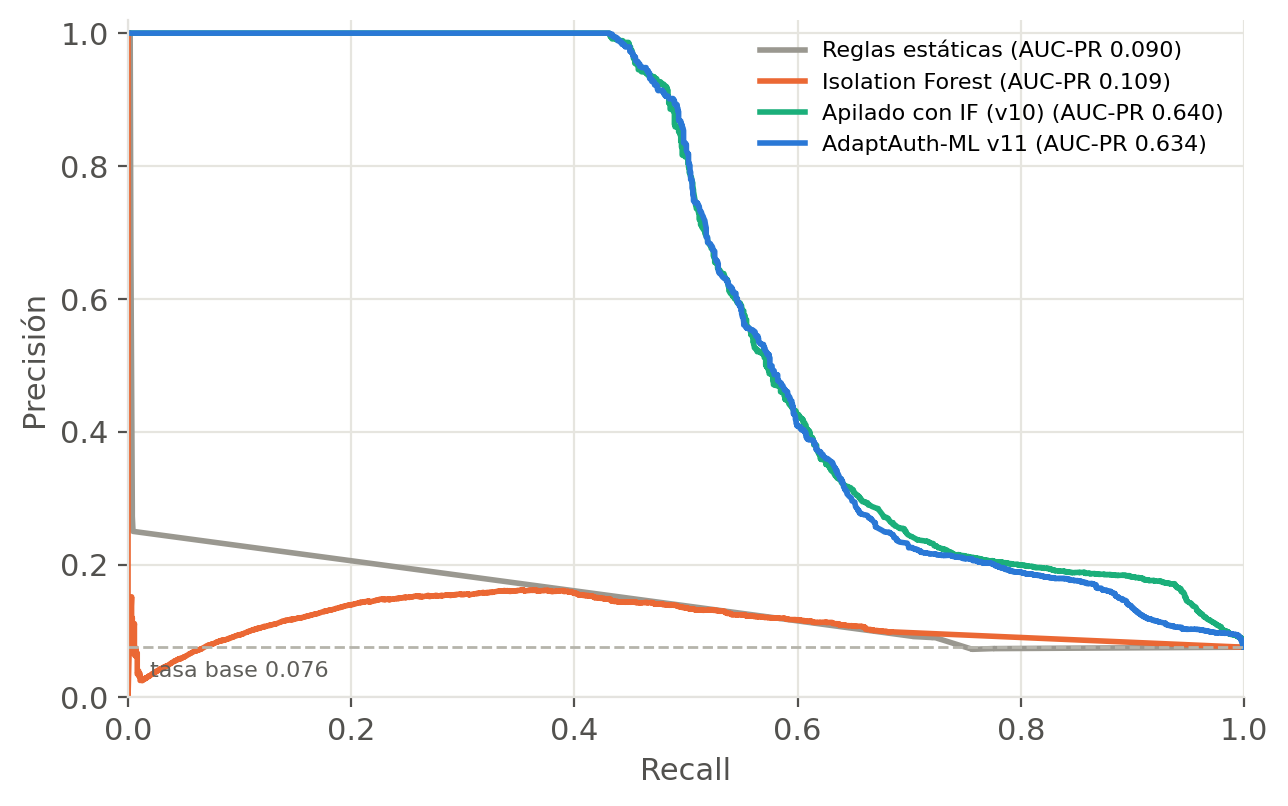

### Pruebas pareadas sobre 14 grupos y bootstrap por usuario

,comparación,prueba,estadístico,p,Shapiro p
0,supervisado_vs_reglas,t de Student pareada,33.87,4.57e-14,0.402
1,supervisado_vs_iforest,t de Student pareada,38.03,1.03e-14,0.485
2,apilado_vs_supervisado,t de Student pareada,-2.10,0.056,0.741


,comparación,dif. media de F1,IC 95 %
0,supervisado_vs_reglas,0.620,"[0.568, 0.665]"
1,apilado_vs_supervisado,-0.008,"[-0.014, -0.002]"


In [5]:
display(Markdown("### Comparación en prueba (meta: F1 ≥ 0.60)"))
display(pd.read_csv("results_complementarios/ablacion_sl.csv").round(3))
display(Image("results_complementarios/curva_pr_modelos_sl.png", width=800))
j = json.load(open("results_complementarios/analisis_complementario.json"))
display(Markdown("### Pruebas pareadas sobre 14 grupos y bootstrap por usuario"))
display(pd.DataFrame([{"comparación": k, "prueba": v["prueba"], "estadístico": round(v["estadistico"], 2),
                       "p": f'{v["p_valor"]:.3g}', "Shapiro p": round(v["shapiro_p_diferencias"], 3)}
                      for k, v in j["pareadas_14_grupos"].items()]))
display(pd.DataFrame([{"comparación": k, "dif. media de F1": round(v["dif_media"], 3),
                       "IC 95 %": [round(x, 3) for x in v["ic95"]]} for k, v in j["bootstrap_usuarios"].items()]))

## Paso 5. Arranque en frío y recalibración de θ2

**Arranque en frío:** se simula una PYME con pocas etiquetas: solo una fracción de los usuarios de entrenamiento conserva su etiqueta. Isolation Forest se ajusta con todos los eventos, porque no necesita etiquetas.

**θ2:** se compara el umbral de bloqueo con distintas restricciones; la versión 11 usa FPR de bloqueo ≤ 0.1 %.

In [6]:
!python run_levantamiento.py --data "{SL}"

 fraccion                    modelo  auc_roc  auc_pr  auc_pr_de  positivos
    0.000     Isolation Forest solo   0.6297  0.1094        NaN        0.0
    0.005 AdaptAuth-ML v11 (sin IF)   0.7107  0.3733     0.1754       10.0
    0.005      Apilado con IF (v10)   0.7155  0.3754     0.1281       10.0
    0.010 AdaptAuth-ML v11 (sin IF)   0.7416  0.4545     0.0674       15.6
    0.010      Apilado con IF (v10)   0.7525  0.4542     0.0787       15.6
    0.020 AdaptAuth-ML v11 (sin IF)   0.7831  0.5404     0.0709       46.6
    0.020      Apilado con IF (v10)   0.7881  0.5338     0.0701       46.6
    0.050 AdaptAuth-ML v11 (sin IF)   0.8133  0.5353     0.0941      159.0
    0.050      Apilado con IF (v10)   0.8163  0.5417     0.0704      159.0
    0.100 AdaptAuth-ML v11 (sin IF)   0.8023  0.5524     0.0463      312.8
    0.100      Apilado con IF (v10)   0.8052  0.5568     0.0354      312.8
    0.250 AdaptAuth-ML v11 (sin IF)   0.8123  0.5988     0.0153      754.0
    0.250      Apilado co

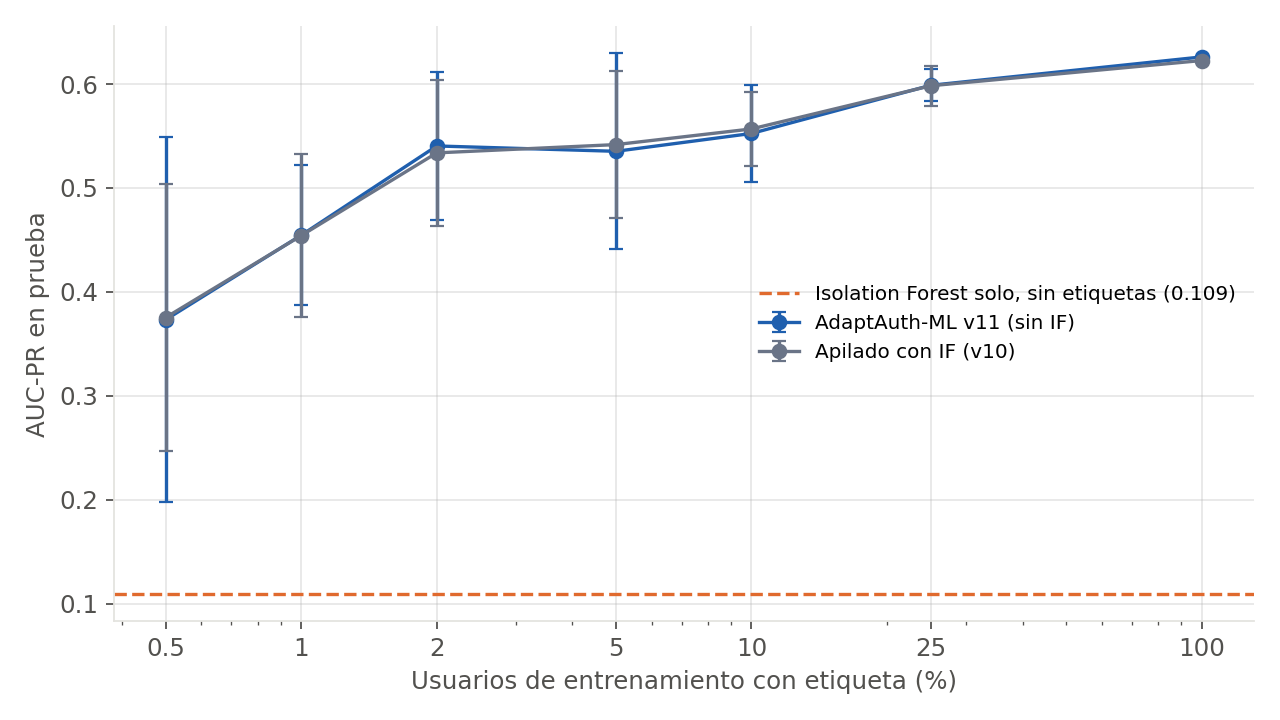

,fraccion,dif_auc_pr_media,dif_min,dif_max,semillas_a_favor_apilado
0,0.005,0.0021,-0.0588,0.0740,2
1,0.010,-0.0003,-0.1235,0.0430,3
2,0.020,-0.0066,-0.0281,0.0128,2
3,0.050,0.0065,-0.0135,0.0497,1
4,0.100,0.0043,-0.0045,0.0245,3
5,0.250,-0.0004,-0.0074,0.0061,3
6,1.000,-0.0035,-0.0035,-0.0035,0


### Matriz de decisiones en prueba según la regla de θ2

,regla_theta2,theta1,theta2,acceso_legitimos,acceso_anomalos,otp_legitimos,otp_anomalos,bloqueo_legitimos,bloqueo_anomalos,f1_theta1,fpr_theta1,precision_bloqueo,recall_bloqueo,f1_theta2,fpr_bloqueo
0,FPR de bloqueo ≤ 1 % (v10),0.21,0.27,19138,792,52,15,85,770,0.6283,0.0071,0.9006,0.4883,0.6332,0.0044
1,FPR de bloqueo ≤ 0.5 %,0.21,0.40,19138,792,102,64,35,721,0.6283,0.0071,0.9537,0.4572,0.6181,0.0018
2,FPR de bloqueo ≤ 0.1 % (v11),0.21,0.56,19138,792,128,90,9,695,0.6283,0.0071,0.9872,0.4407,0.6094,0.0005
3,Precisión de bloqueo ≥ 0.95,0.21,0.54,19138,792,127,88,10,697,0.6283,0.0071,0.9859,0.4420,0.6103,0.0005


In [7]:
display(Image("results_levantamiento/arranque_en_frio_sl.png", width=760))
display(pd.read_csv("results_levantamiento/arranque_en_frio_diferencias.csv").round(4))
display(Markdown("### Matriz de decisiones en prueba según la regla de θ2"))
display(pd.read_csv("results_levantamiento/recalibracion_theta2_sl.csv").round(4))

## Paso 6. Verificación de requisitos no funcionales

RNF-04 y RNF-05 en la misma corrida de 1 000 eventos; contingencia, registro, explicación SHAP, reentrenamiento y privacidad.

In [8]:
!python run_requisitos_sl.py --data "{SL}"

{'nombre': 'AdaptAuth-ML v11 (supervisado, sin IF)', 'theta1': 0.21, 'theta2': 0.56, 's_ref': None, 'theta1_f1': 0.6282513005202081, 'theta1_precision': 0.851409978308026, 'theta1_recall': 0.49778059606848446, 'theta1_fpr': 0.007107652399481194, 'theta2_f1': 0.6093818500657606, 'theta2_fpr': 0.0004669260700389105}
  codigo                           requisito                         meta                                           resultado  cumple
  RNF-01      Efectividad en identidad y red                   F1 >= 0.60                                               0.628    True
  RNF-03                      Falsas alarmas FPR <= 5 %; bloqueo <= 0.1 %                                        0.71%; 0.05%    True
  RNF-04            Inferencia C2 a C3 (p99)                    <= 100 ms                           6.7 ms (p50 3.3; p95 5.3)    True
  RNF-05             Respuesta C1 a C4 (p99)                    <= 200 ms                         16.0 ms (p50 8.9; p95 14.1)    True
  RNF-06      

In [9]:
display(pd.read_csv("results_requisitos_sl/matriz_cumplimiento_requisitos.csv"))
reg = pd.read_csv("results_requisitos_sl/registro_eventos_prueba.csv")
display(pd.crosstab(reg["decision"], reg["etiqueta"].map({0: "legítimo", 1: "sospechoso"})))
display(pd.read_csv("results_requisitos_sl/explicacion_alertas_top3.csv").sort_values("score_R", ascending=False).head(8))

,codigo,requisito,meta,resultado,cumple
0,RNF-01,Efectividad en identidad y red,F1 >= 0.60,0.628,True
1,RNF-03,Falsas alarmas,FPR <= 5 %; bloqueo <= 0.1 %,0.71%; 0.05%,True
2,RNF-04,Inferencia C2 a C3 (p99),<= 100 ms,6.7 ms (p50 3.3; p95 5.3),True
3,RNF-05,Respuesta C1 a C4 (p99),<= 200 ms,16.0 ms (p50 8.9; p95 14.1),True
4,RNF-06,Contingencia P1 (CA-C4-02),OTP en 100 % de fallos,100 %,True
5,RNF-07,Media de R en legítimos,< 0.30,0.024,True
6,RNF-08,Reentrenamiento 500 000 eventos,<= 15 min,1.58 min,True
7,RNF-09,Partición sin fuga,Temporal; variables causales,Temporal dic-mar/abr/may-jun; 3 variables excl...,True
8,RNF-10,Top-3 variables por alerta,100 % de alertas,922 de 922 (3.21 ms c/u),True
9,RNF-12,Sin identificadores directos,0 coincidencias,0 coincidencias de correo o IP,True


etiqueta,legítimo,sospechoso
decision,,
acceso_directo,19138,792
bloqueo,9,695
otp,128,90


,record_id,score_R,decision,etiqueta,variable_1,variable_2,variable_3
606,63022,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d
392,56879,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d
182,50302,0.998,bloqueo,1,ip_country_Chile,continent_Americas,ip_country_Brazil
315,54728,0.998,bloqueo,1,ip_country_Chile,continent_Americas,ip_country_Brazil
761,68435,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d
805,69739,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d
189,50397,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d
148,49021,0.998,bloqueo,1,ip_country_Chile,continent_Americas,distinct_ips_30d


## Paso 7. CERT Insider Threat r4.2: historial del empleado

Organización sintética de 1 000 empleados (Carnegie Mellon University). Validación cruzada de 5 grupos de empleados. Los datos se leen desde **Mi unidad → AdaptAuth-ML → CERT_r4.2** y los resultados se copian a **Mi unidad → AdaptAuth-ML → resultados_v11**.

In [11]:
from google.colab import drive
drive.mount("/content/drive")
CERT = "/content/drive/MyDrive/AdaptAuth-ML/CERT_r4.2"
!python run_cert_v2.py --dir "{CERT}" --frio
!mkdir -p /content/drive/MyDrive/AdaptAuth-ML/resultados_v11
!cp -r results_cert_v11 results_levantamiento /content/drive/MyDrive/AdaptAuth-ML/resultados_v11/

Mounted at /content/drive
[CERT r4.2 v2] 330,452 días-empleado | 115 días maliciosos | 27 variables | días maliciosos por fold: [21, 24, 22, 21, 27] | 45s
  fold 1/5: prueba 201 empleados, 21 días maliciosos | reglas_estaticas: F1=0.01 | iforest: F1=0.00 | supervisado: F1=0.30 | hibrido: F1=0.22 | hibrido_apilado: F1=0.25
  fold 2/5: prueba 201 empleados, 24 días maliciosos | reglas_estaticas: F1=0.01 | iforest: F1=0.00 | supervisado: F1=0.48 | hibrido: F1=0.48 | hibrido_apilado: F1=0.60
  fold 3/5: prueba 200 empleados, 22 días maliciosos | reglas_estaticas: F1=0.00 | iforest: F1=0.00 | supervisado: F1=0.51 | hibrido: F1=0.67 | hibrido_apilado: F1=0.61
  fold 4/5: prueba 199 empleados, 21 días maliciosos | reglas_estaticas: F1=0.01 | iforest: F1=0.01 | supervisado: F1=0.19 | hibrido: F1=0.21 | hibrido_apilado: F1=0.19
  fold 5/5: prueba 199 empleados, 27 días maliciosos | reglas_estaticas: F1=0.01 | iforest: F1=0.01 | supervisado: F1=0.45 | hibrido: F1=0.45 | hibrido_apilado: F1=0.41


,modelo,auc_roc,auc_pr,f1_theta1,recall_theta1,fpr_theta1
0,Reglas estáticas,0.8990,0.0028,0.0064,0.3913,0.0420
1,Isolation Forest,0.9435,0.0070,0.0080,0.2870,0.0246
2,AdaptAuth-ML v11,0.9629,0.2682,0.3655,0.6261,0.0006
3,Híbrido lineal,0.9732,0.2623,0.3804,0.5739,0.0005
4,Apilado con IF (v10),0.9471,0.2556,0.3777,0.6174,0.0006


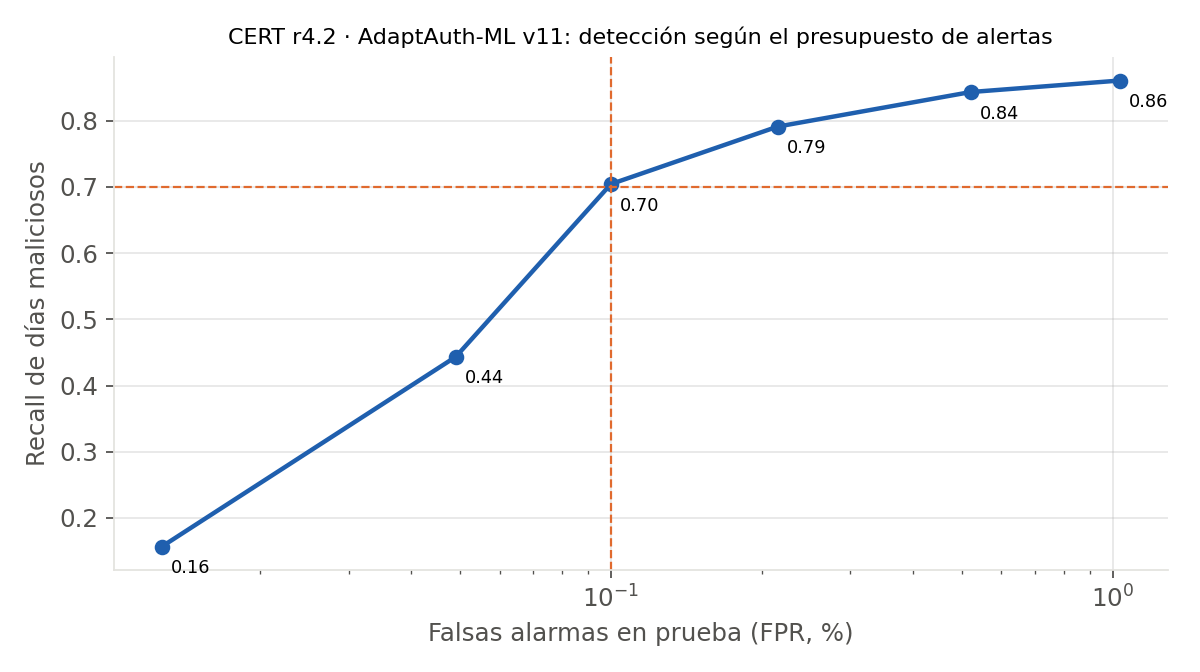

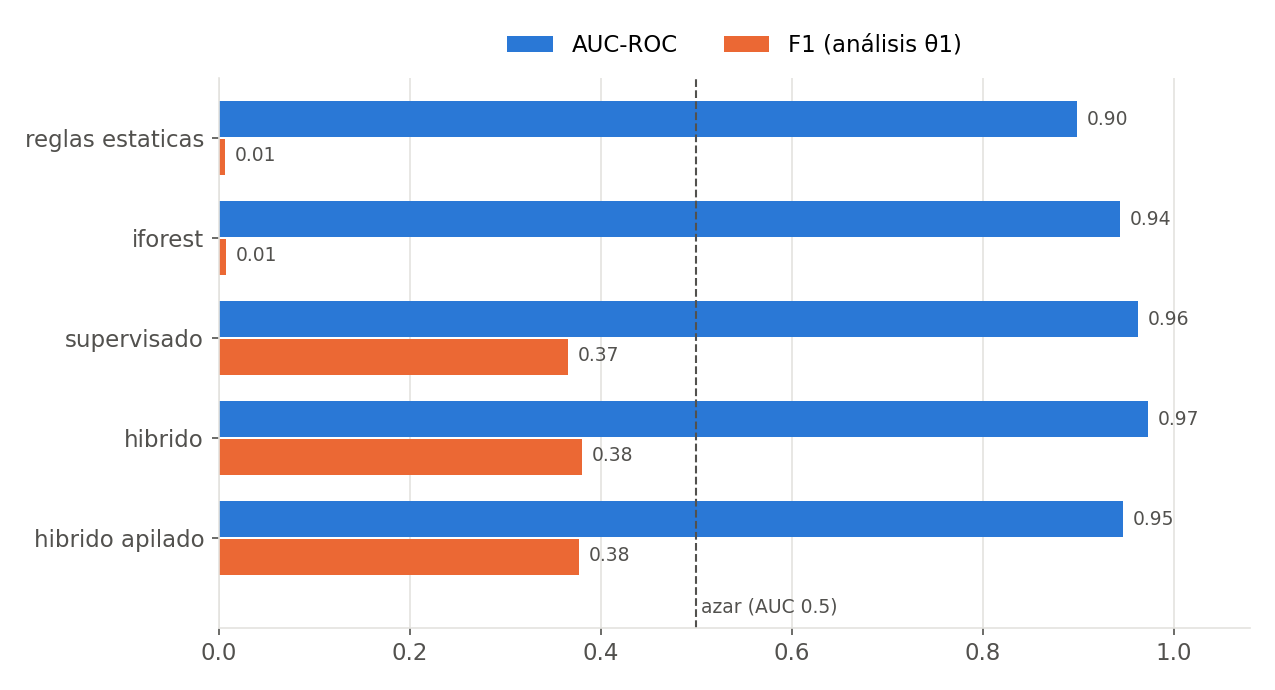

,fraccion,auc_pr_adaptauth,auc_pr_apilado,auc_pr_iforest
0,0.2,0.1132,0.1045,0.0082
1,0.5,0.2151,0.2241,0.0082


In [12]:
c = pd.read_csv("results_cert_v11/tabla_comparativa_cert_v2.csv")
c["modelo"] = c["modelo"].replace({"supervisado": "AdaptAuth-ML v11", "hibrido_apilado": "Apilado con IF (v10)",
                                   "hibrido": "Híbrido lineal", "reglas_estaticas": "Reglas estáticas", "iforest": "Isolation Forest"})
display(c[["modelo", "auc_roc", "auc_pr", "f1_theta1", "recall_theta1", "fpr_theta1"]].round(4))
display(Image("results_cert_v11/figuras/puntos_operacion_cert_v11.png", width=760))
display(Image("results_cert_v11/figuras/comparacion_modelos_cert_v2.png", width=760))
display(pd.read_csv("results_cert_v11/arranque_en_frio_cert.csv").round(4))

## Resumen

Los resultados de cada paso se generan en esta corrida. Código y resultados: [github.com/AshlyChavez/adaptauth-ml](https://github.com/AshlyChavez/adaptauth-ml)